# Application: turn browser receipts into Python values

Run this tutorial cell by cell in nbinlineai JupyterLab with a live Python kernel. Camera and microphone calls may show browser permission prompts; choose a safe scene and say a short test phrase. Each browser call returns immediately. Move to its later inspection cell after the visible operation finishes, and rerun that inspection if still active. No cell waits inside the kernel. AI questions use a configured model and may incur charges. There are no saved outputs or AI answers in this source notebook.

An unattended worked run can use a synthetic canvas as its camera scene and generated silent audio for microphone calls. Such a run demonstrates real nbinlineai receipts, Python values, and model answers in an isolated notebook; it does not test physical devices, spoken narration, or operating-system permission decisions.

A regular Python function returns its value at once. A browser receipt is mutable: `status` and `result` can change after the call cell has finished. The printed result of the call cell is just an early snapshot.

These media APIs require nbinlineai 0.1.16 or a Git-source installation containing them. If 0.1.16 is not yet available from PyPI, use the [main source setup](https://rahuldave.com/nbinlineai/development.html#set-up-from-source); 0.1.15 does not include these additions. Use your notebook’s selected image-capable connection for image questions.


In [1]:
from pathlib import Path
from uuid import uuid4
from PIL import Image
from nbinlineai.browser_receipt import MediaClip
from nbinlineai.tools import (browser_capabilities, operation_status, start_camera,
    capture_camera, stop_source, record_microphone, release_media, attach_media)

work = Path.cwd() / f'receipts-demo-{uuid4().hex[:10]}'
work.mkdir()  # An owned Python output folder; browser captures stay in memory.

def require_complete(receipt, label):
    print(label, 'state:', receipt.status, 'operation:', receipt.operation_id)
    if receipt.status != 'completed':
        raise RuntimeError(f'{label}: inspect again after the browser finishes; error={receipt.error}')
    return receipt.result

def with_tax(price: float, rate: float) -> float:
    """Return a tax-inclusive price as an ordinary Python number."""
    return round(price * (1 + rate), 2)

ordinary_value = with_tax(12.50, 0.08)
print('Ordinary Python value:', ordinary_value)


Ordinary Python value: 13.5


Available to the next AI question:
- &`with_tax` — return a Python number from an ordinary function.

This ordinary Markdown cell is a tool declaration. Its Tools control should be on for the next question. The function must still exist in the live kernel.


Call `with_tax` once with `price=12.50` and `rate=0.08`. Report the returned number and say that it is an ordinary Python value, with no browser operation ID.


`with_tax(price=12.50, rate=0.08)` returned **13.5**. It’s an ordinary Python value with no browser operation ID.

**Observed live tool calls for the answer above** (actual subscription events; private fields shortened).

| Tool | Result state | Submitted arguments | Observed result |
| --- | --- | --- | --- |
| `with_tax` | completed | {"price":12.5,"rate":0.08} | 13.5 |


For the browser questions below, turn **Tools off** on the earlier `with_tax` declaration if you want a smaller menu. The next questions declare only `browser_capabilities` and `operation_status` directly; the unique inherited tool count stays well below 20.


In [2]:
capability_receipt = browser_capabilities()
capability_receipt  # Early rendered state; this output will not refresh itself.


BrowserReceipt(operation_id=None, status='running')

In [3]:
capability_data = require_complete(capability_receipt, 'capabilities')
print('Secure browser context:', capability_data['secure_context'])
print('Memory recording limit (seconds):', capability_data['limits']['recording_memory_seconds'])


capabilities state: completed operation: AdVelYZCgA0QX345ZeX1M1nOq2Vv6x_E
Secure browser context: True
Memory recording limit (seconds): 60


In [4]:
status_receipt = operation_status(capability_receipt.operation_id)
status_receipt


BrowserReceipt(operation_id=None, status='running')

In [5]:
snapshot = require_complete(status_receipt, 'status lookup')
print('Lookup receipt:', status_receipt.status, status_receipt.operation_id)
print('Target snapshot:', snapshot['status'], snapshot['operation_id'])
assert snapshot['operation_id'] == capability_receipt.operation_id


status lookup state: completed operation: AdVelYZCgA0QX345ZeX1M1nOq2Vv6x_E
Lookup receipt: completed AdVelYZCgA0QX345ZeX1M1nOq2Vv6x_E
Target snapshot: completed AdVelYZCgA0QX345ZeX1M1nOq2Vv6x_E


`operation_status` has **two states**: its own lookup receipt is `completed`, while `status_receipt.result` is a snapshot of the target. A completed lookup can report a still-running target. This snapshot contains metadata, not decoded media bytes. Inspect the original capture receipt later for `.result`.


Call &`browser_capabilities` once. Give its actual operation ID and current state. If the call has not completed, stop there; do not claim a limit yet.


Operation ID: `3tmz2E49IBgfECGJEZB3ZZNScJP4AXvs`. State: **completed**.

**Observed live tool calls for the answer above** (actual subscription events; private fields shortened).

| Tool | Result state | Submitted arguments | Observed result |
| --- | --- | --- | --- |
| `browser_capabilities` | completed | {} | {"operation_id":"3tmz2E49IBgfECGJEZB3ZZNScJP4AXvs","secure_context":true,"permissions":{"camera":"prompt","microphone":"prompt"},"file_media_supported":true,"operations":{"browser_capabilities":true,"operation_status":true,"cancel_operation":true,"save_media":true,"release_media":true,"list_media_sources":true,"start_camera":true,"start_microphone":true,"capture_camera":true,"stop_source":true,"start_recording":true,"pause_recording":true,"resume_recording":true,"stop_recording":true,"record_camera":true,"record_microphone":true,"read_audio_levels":true,"setup_share":true,"start_share":true,"capture_screen":true,"capture_tool":true,"stop_share":true,"list_outputs":true,"read_output":true,"ex |


After the prior browser capability operation finishes, call &`operation_status` using that **exact operation ID** from the previous answer. Report both the lookup state and the target snapshot state, and one actual memory recording limit only if the target completed. This AI call does not assign Python variables.


The `operation_status` call returned `completed` for operation `3tmz2E49IBgfECGJEZB3ZZNScJP4AXvs`. Its result was only `{"checked": true}`, so it did not provide a separate target snapshot state or a memory recording limit.

**Observed live tool calls for the answer above** (actual subscription events; private fields shortened).

| Tool | Result state | Submitted arguments | Observed result |
| --- | --- | --- | --- |
| `operation_status` | completed | {"operation_id":"3tmz2E49IBgfECGJEZB3ZZNScJP4AXvs"} | {"operation_id":"3tmz2E49IBgfECGJEZB3ZZNScJP4AXvs","status":"completed","result":{"checked":true}} |


## Camera image: descriptor and Pillow value

Grant camera access only if you choose. Start a source, inspect it on a later kernel turn, then capture a still. `save_to=None` keeps the browser result in memory; no server-relative file is generated.


In [6]:
camera_start = start_camera(audio=False)
camera_start


BrowserReceipt(operation_id=None, status='running')

In [7]:
camera_info = require_complete(camera_start, 'camera start')
camera_source_id = camera_info['source_id']
print('Active camera source:', camera_source_id)


camera start state: completed operation: wT299nNEdmgeugMcqWWXNOUBXmtPBDA_
Active camera source: [private device detail]


In [8]:
photo_receipt = capture_camera(source_id=camera_source_id, save_to=None, max_size=960)
photo_receipt


BrowserReceipt(operation_id=None, status='running')

camera photo state: completed operation: uahGONIOOVJv2PG2So84wAXxDUqrE-s6
Descriptor keys: ['bytes', 'expires_at', 'height', 'media_id', 'mime_type', 'sha256', 'width']
Real Pillow image: (960, 576) RGBA
Python copy: [temporary local path]


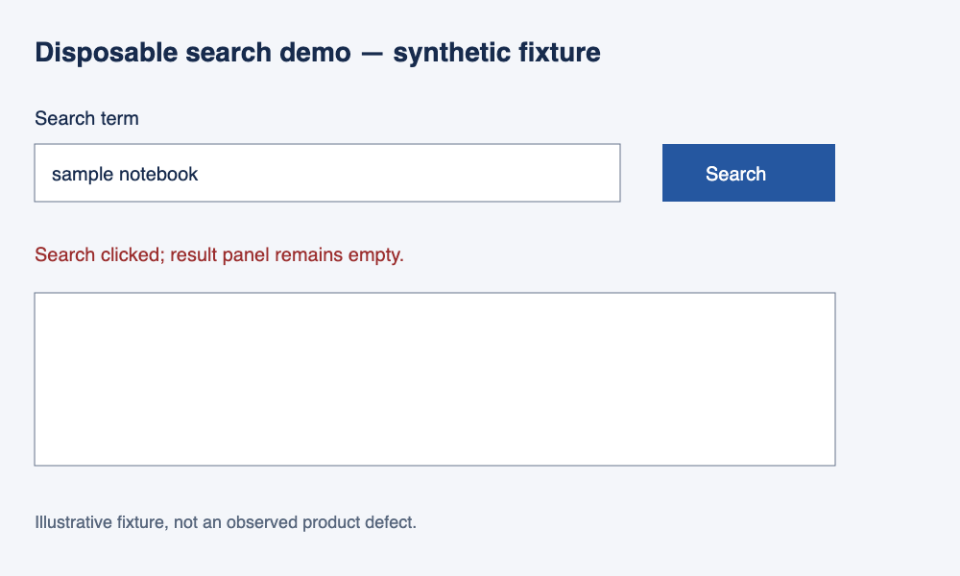

In [9]:
photo = require_complete(photo_receipt, 'camera photo')
assert isinstance(photo, Image.Image)
assert isinstance(photo_receipt.media, dict)
photo_ref = {'media_id': photo_receipt.media['media_id']}
print('Descriptor keys:', sorted(photo_receipt.media))
print('Real Pillow image:', photo.size, photo.mode)
photo_path = work / 'camera-photo.png'
photo.save(photo_path, format='PNG')
print('Python copy:', photo_path)
display(photo)


`photo_receipt.media` is a managed descriptor with an ID, MIME type, hash and byte count. It can identify media for another browser tool, but is not the image itself. `photo_receipt.result` is the decoded Pillow image. The Python copy above survives a later `release_media` call. `operation_status(photo_receipt.operation_id)` would return a snapshot with the descriptor, not this Pillow object.


In [10]:
camera_stop = stop_source(camera_source_id)
camera_stop


BrowserReceipt(operation_id=None, status='running')

In [11]:
print('Stop control result:', require_complete(camera_stop, 'camera stop'))


camera stop state: completed operation: i2RznlTuSAGpRpJvUtnCit3bRJTv0TGv
Stop control result: {'source_id': '[opaque hardware reference]', 'stopped': True}


## Microphone clip: descriptor and encoded bytes

Speak a short phrase after granting microphone access. The bounded one-shot recording closes its own source. It does not transcribe speech. Use a later cell after its visible media row finishes.


In [12]:
audio_receipt = record_microphone(save_to=None, duration=6)
audio_receipt


BrowserReceipt(operation_id=None, status='running')

In [13]:
clip = require_complete(audio_receipt, 'microphone recording')
assert isinstance(clip, MediaClip)
assert isinstance(audio_receipt.media, dict)
print('Clip MIME:', clip.mime_type, 'bytes:', len(clip.data), 'duration:', clip.duration_seconds)
print('Managed media ID:', audio_receipt.media['media_id'])
suffix = {'audio/webm': '.webm', 'audio/mp4': '.m4a', 'audio/ogg': '.ogg'}.get(clip.mime_type.split(';', 1)[0])
if suffix is None:
    raise ValueError(f'Unsupported audio MIME for a portable copy: {clip.mime_type}')
audio_path = work / f'microphone{suffix}'
audio_path.write_bytes(clip.data)
print('Python copy:', audio_path)


microphone recording state: completed operation: 4Pp2257_50xCecfrNea0RgrkqEnKpoaF
Clip MIME: audio/webm;codecs=opus bytes: 1641 duration: 6
Managed media ID: 3PisXn_2u34HqT2KI6Qf77ditIOJuw2M
Python copy: [temporary local path]


## Optional model view of the still

A tool result descriptor does not show the model photo pixels or audio. The direct call below asks for visible confirmation to attach **only this still** to the stable target question. Inspect the attachment receipt after you click Attach image; then run the target question yourself. Never attach a private capture without reviewing it first. Audio and video are not supported model attachments here.


In [14]:
photo_attachment = attach_media(photo_ref, 'receipts-image-question', detail='auto')
photo_attachment


BrowserReceipt(operation_id=None, status='running')

In [15]:
print('Attachment confirmation:', require_complete(photo_attachment, 'photo attachment'))


photo attachment state: completed operation: 4_p5MtYIGJeIg4iAJaww7LHkyFmrbFxF
Attachment confirmation: {'confirmed': True, 'question_cell_id': 'receipts-image-question', 'image_sha256': '9bbaa31f2f6f11b1e3b672e5f9fffd9854f678bfc51ccb6600044503567e6878', 'detail': 'auto'}


Describe the attached camera still in one sentence. If no image indicator is present, say that you cannot inspect the pixels. Do not infer image content from the earlier `photo_receipt.media` descriptor.


The attached still shows a synthetic search demo with “sample notebook” entered and an empty results panel after Search was clicked.

## Release temporary browser media

Run after the image question and after the Python copies exist. These calls release only the two managed media IDs created here; they do not delete the files in `work`. Remove the optional image attachment with the question's UI before releasing it if you intend to rerun that question.


In [16]:
photo_release = release_media(photo_receipt.media['media_id'])
audio_release = release_media(audio_receipt.media['media_id'])


In [17]:
print('Photo release:', require_complete(photo_release, 'photo release'))
print('Audio release:', require_complete(audio_release, 'audio release'))
print('Kept Python files:', [p.name for p in work.iterdir()])


photo release state: completed operation: 5xJX7CXIC78mpFVz62wi7RspAGpLvNgY
Photo release: {'released': True}
audio release state: completed operation: f8zxQAtnmLfRI8zfR-8mIDCTKWPrQF92
Audio release: {'released': True}
Kept Python files: ['microphone.webm', 'camera-photo.png']
